In [1]:
import numpy as np
import torch

#Loading reference posterior parameters
with np.load("radial_reference.npz") as data:
    observed = data["observed"].copy()
    uncertainty = data["uncertainty"].copy()
    usable = data["usable"].copy()
    theta_true = data["theta_true"].copy()

    #Prior constrains
    prior_low = data["prior_low"].copy()
    prior_high = data["prior_high"].copy()

# Simulate data

In [2]:
from cosmology import Cosmology
from lensing import simulate_map
from compression import project_shear, radial_compression

# Load the exact observing setup used for the reference posterior.
with np.load("radial_reference.npz") as data:
    observed = data["observed"].copy()
    usable = data["usable"].copy()
    theta_true = data["theta_true"].copy()

    prior_low = data["prior_low"].copy()
    prior_high = data["prior_high"].copy()

    x = data["x"].copy()
    y = data["y"].copy()
    bin_edges = data["bin_edges"].copy()

    pixel_mask = data["pixel_valid"].copy()
    count_map = data["count_map"].copy()
    sigma_galaxy = float(data["sigma_galaxy"])

    true_centre = data["true_centre"].copy()
    assumed_centre = data["assumed_centre"].copy()
    z_lens = float(data["z_lens"])
    z_source = float(data["z_source"])

    cosmology = Cosmology(
        H0=float(data["H0"]),
        Omega_m=float(data["Omega_m"]),
        Omega_lambda=float(data["Omega_lambda"]),
    )

Sigma_crit = cosmology.critical_surface_density(z_lens, z_source)

# The held-out observation used to condition the SBI posterior.
observed_radial = torch.as_tensor(
    observed[usable], dtype=torch.float32
)
true_parameters = theta_true

def simulate_radial(theta):
    # Generate a noisy map for this parameter pair.
    g_obs_map, _, pixel_sigma, pixel_valid = simulate_map(
        theta=theta,
        x=x,
        y=y,
        centre=true_centre,
        mask=pixel_mask,
        z_l=z_lens,
        Sigma_crit=Sigma_crit,
        cosmology=cosmology,
        N_per_pixel=count_map,
        sigma_galaxy=sigma_galaxy,
    )

    # Obtain the quantities needed for compression.
    radius, angle, gt, gx = project_shear(
        g_obs_map, x, y, assumed_centre
    )

    radial_result = radial_compression(
        gt, radius, pixel_sigma, pixel_valid, bin_edges
    )

    assert np.all(radial_result.valid[usable])

    result = torch.as_tensor(
        radial_result.shear[usable],
        dtype=torch.float32,
    )
    assert torch.isfinite(result).all()

    return result


# Call the function to generate one example.
training_radial = simulate_radial(true_parameters)

print(training_radial.shape)
assert training_radial.shape == observed_radial.shape



torch.Size([15])


## Repeat and build the training set

In [3]:
from sbi.utils import BoxUniform
prior = BoxUniform(low = torch.as_tensor(prior_low, dtype=torch.float32),
                   high = torch.as_tensor(prior_high,dtype=torch.float32),)
num_simulations = 5000
theta_train = prior.sample((num_simulations,))

x_train = torch.stack(
    [simulate_radial(theta_i) for theta_i in theta_train],
    dim=0,
)

#Check
print("theta.shape",theta_train.shape)  # torch.Size([num_simulations, 2])
print("x.shape",x_train.shape)      # torch.Size([num_simulations, 15])

assert x_train.shape[1:] == observed_radial.shape
assert torch.isfinite(x_train).all()


theta.shape torch.Size([5000, 2])
x.shape torch.Size([5000, 15])


# Training the neural network

 Neural network successfully converged after 132 epochs.

  0%|          | 0/5000 [00:00<?, ?it/s]

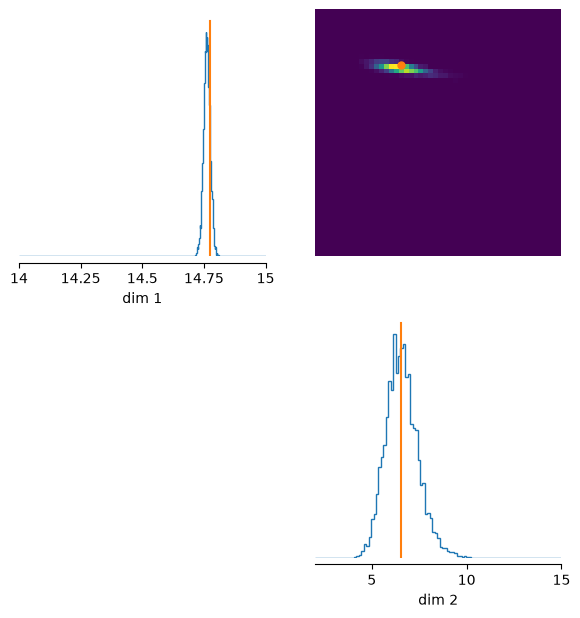

In [4]:
from sbi.inference import NPE
from sbi.analysis import pairplot

inference = NPE(prior=prior)
density_estimator = inference.append_simulations(
    theta_train, x_train
).train()
posterior = inference.build_posterior(density_estimator)

posterior_samples = posterior.sample((5000,), x = observed_radial)

_ = pairplot(
    samples=posterior_samples,
    points=torch.as_tensor(theta_true, dtype=torch.float32)[None, :],  # `points` needs a batch dimension.
    limits=[[14.0, 15.0], [2.0, 15.0]],
    figsize=(7, 7),
)

# Infer the neural network

## Validating the network


SBI
Mean: [14.760896  6.575528]
Standard deviation: [0.01335333 0.8489285 ]
16%, 50%, 84%: [[14.74793205  5.75057835]
 [14.76100492  6.5333488 ]
 [14.77403847  7.38440279]]
Correlation: -0.6937454076558978

Grid
Mean: [14.75917559  6.77894783]
Standard deviation: [0.01320524 0.90787461]
16%, 50%, 84%: [[14.7458194   5.89130435]
 [14.75919732  6.7173913 ]
 [14.77257525  7.65217391]]
Correlation: -0.6224825331947381


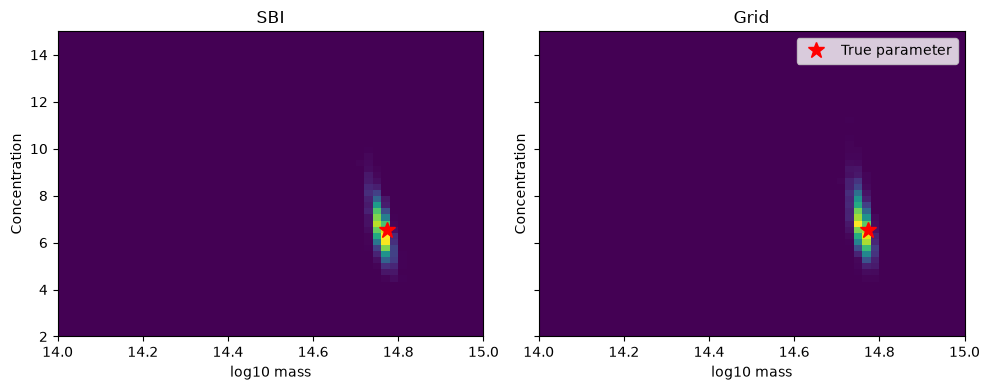

In [5]:
import matplotlib.pyplot as plt

with np.load("radial_reference.npz") as data:
    grid_probability = data["posterior"].copy()
    mass_grid = data["log_mass_grid"].copy()
    concentration_grid = data["concentration_grid"].copy()

sbi_samples = posterior_samples.detach().cpu().numpy()

# Draw parameter pairs from the saved grid probabilities.
weights = grid_probability.ravel()
weights = weights / weights.sum()

rng = np.random.default_rng(42)
flat_indices = rng.choice(
    weights.size, size=len(sbi_samples), p=weights
)
mass_indices, concentration_indices = np.unravel_index(
    flat_indices, grid_probability.shape
)

grid_samples = np.column_stack((
    mass_grid[mass_indices],
    concentration_grid[concentration_indices],
))

# Compare centre, spread, and mass–concentration correlation.
for name, samples in [
    ("SBI", sbi_samples),
    ("Grid", grid_samples),
]:
    print(f"\n{name}")
    print("Mean:", samples.mean(axis=0))
    print("Standard deviation:", samples.std(axis=0))
    print("16%, 50%, 84%:", np.quantile(
        samples, [0.16, 0.50, 0.84], axis=0
    ))
    print("Correlation:", np.corrcoef(samples.T)[0, 1])

# Compare their shapes using identical axes.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

for ax, name, samples in zip(
    axes, ["SBI", "Grid"], [sbi_samples, grid_samples]
):
    ax.hist2d(
        samples[:, 0], samples[:, 1],
        bins=50,
        range=[[14, 15], [2, 15]],
    )
    ax.plot(theta_true[0], theta_true[1], "r*", markersize=12, label = "True parameter")
    ax.set(
        title=name,
        xlabel="log10 mass",
        ylabel="Concentration",
    )
ax.legend()
plt.tight_layout()
plt.show()

### Posterior predictive check

torch.Size([100, 15])
Median: tensor([-0.0051,  0.0021,  0.0048,  0.0108,  0.0192,  0.0284,  0.0377,  0.0358,
         0.0317,  0.0272,  0.0232,  0.0191,  0.0158,  0.0129,  0.0104])
16th percentile: tensor([-0.0109, -0.0036,  0.0001,  0.0061,  0.0162,  0.0252,  0.0352,  0.0334,
         0.0296,  0.0258,  0.0218,  0.0179,  0.0148,  0.0120,  0.0097])
84th percentile: tensor([0.0015, 0.0085, 0.0094, 0.0143, 0.0218, 0.0314, 0.0400, 0.0381, 0.0333,
        0.0286, 0.0242, 0.0202, 0.0169, 0.0137, 0.0113])


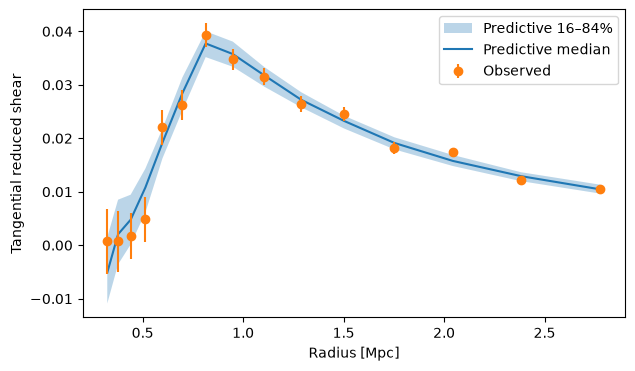

In [ ]:
posterior_check = posterior_samples[:100]
predictive_check = torch.stack([
    simulate_radial(theta) for theta in posterior_check
])
print(predictive_check.shape)  # (100, 15)

median = torch.quantile(predictive_check, 0.5, dim=0)
p16 = torch.quantile(predictive_check, 0.16, dim=0)
p84 = torch.quantile(predictive_check, 0.84, dim=0)

print("Median:", median)
print("16th percentile:", p16)
print("84th percentile:", p84)

# Plot against the centres of the usable radial bins.
radii = np.sqrt(bin_edges[:-1] * bin_edges[1:])[usable]

plt.figure(figsize=(7, 4))
plt.fill_between(radii, p16.numpy(), p84.numpy(),
                 alpha=0.3, label="Predictive 16–84%")
plt.plot(radii, median.numpy(), label="Predictive median")
plt.errorbar(
    radii, observed_radial.numpy(),
    yerr=uncertainty[usable],
    fmt="o", label="Observed",
)
plt.xlabel("Radius [Mpc]")
plt.ylabel("Tangential reduced shear")
plt.legend()
plt.show()

### Calibration on fresh simulated observations

In [8]:
#Draw a known mass and concentration from the prior
theta_test = prior.sample((1,))[0]
print(theta_test)        # [log_mass, concentration]
print(theta_test.shape)  # torch.Size([2])

#New 15-bin profile
x_test = simulate_radial(theta_test)
print(x_test.shape)      # torch.Size([15])

#Give the profile to the trained posterior
test_samples = posterior.sample((1000,), x=x_test)
lower = torch.quantile(test_samples, 0.05, dim=0)
upper = torch.quantile(test_samples, 0.95, dim=0)

inside = (theta_test >= lower) & (theta_test <= upper)

for i, name in enumerate(["log mass", "concentration"]):
    print(
        f"{name}: true={theta_test[i]:.3f}, "
        f"90% interval=[{lower[i]:.3f}, {upper[i]:.3f}], "
        f"inside={inside[i].item()}"
    )

tensor([14.5489, 10.2800])
torch.Size([2])
torch.Size([15])


  0%|          | 0/1000 [00:00<?, ?it/s]

log mass: true=14.549, 90% interval=[14.520, 14.570], inside=True
concentration: true=10.280, 90% interval=[6.762, 12.650], inside=True


In [11]:
n_checks = 300
n_posterior_samples = 1000

below_counts = torch.zeros(2, dtype=torch.int64)
above_counts = torch.zeros(2, dtype=torch.int64)

for _ in range(n_checks):
    theta_test = prior.sample((1,))[0]
    x_test = simulate_radial(theta_test)

    test_samples = posterior.sample(
        (n_posterior_samples,), x=x_test
    )

    lower = torch.quantile(test_samples, 0.05, dim=0)
    upper = torch.quantile(test_samples, 0.95, dim=0)

    below_counts += (theta_test < lower).to(torch.int64)
    above_counts += (theta_test > upper).to(torch.int64)

inside_counts = n_checks - below_counts - above_counts

for i, name in enumerate(["Log mass", "Concentration"]):
    print(f"\n{name}")
    print(f"Inside: {inside_counts[i].item() / n_checks:.1%}")
    print(f"Below interval: {below_counts[i].item() / n_checks:.1%}")
    print(f"Above interval: {above_counts[i].item() / n_checks:.1%}")

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

... (291 outputs left out)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]


Log mass
Inside: 91.0%
Below interval: 5.3%
Above interval: 3.7%

Concentration
Inside: 87.7%
Below interval: 6.7%
Above interval: 5.7%


### SBC

torch.Size([200, 2])
torch.Size([200, 15])


Sampling 200 times (1000,) posterior samples.: 100%|██████████| 200/200 [00:02<00:00, 87.10it/s]


Calculating ranks for 200 SBC samples:   0%|          | 0/200 [00:00<?, ?it/s]

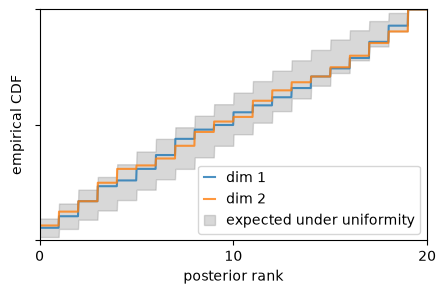

In [13]:
#SBC
from sbi.diagnostics import run_sbc
from sbi.analysis.plot import sbc_rank_plot

num_sbc_samples = 200  # choose a number of sbc runs, should be ~100s
prior_samples = prior.sample((num_sbc_samples,))
prior_predictives = torch.stack([
    simulate_radial(theta) for theta in prior_samples
])

print(prior_samples.shape)      # (200, 2)
print(prior_predictives.shape)  # (200, 15)

# run SBC: for each inference we draw 1000 posterior samples.
num_posterior_samples = 1000
ranks, dap_samples = run_sbc(
    prior_samples,
    prior_predictives,
    posterior,
    num_posterior_samples=num_posterior_samples,
    use_batched_sampling=False,  # `True` can give speed-ups, but can cause memory issues.
)
fig, ax = sbc_rank_plot(
    ranks,
    num_posterior_samples,
    num_bins=20,
    figsize=(5, 3),
)


## Plotting with GetDist

Removed no burn in


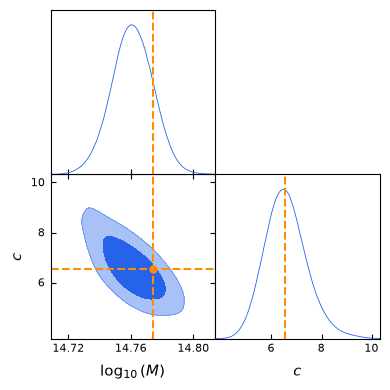

In [16]:
from getdist import MCSamples, plots
import matplotlib.pyplot as plt

names = ["log_mass", "concentration"]

sbi_chain = MCSamples(
    samples=posterior_samples.detach().cpu().numpy(),
    names=names,
    labels=[r"\log_{10}(M)", r"c"],
    ranges={
        "log_mass": [prior_low[0], prior_high[0]],
        "concentration": [prior_low[1], prior_high[1]],
    },
)

g = plots.get_subplot_plotter()
g.triangle_plot(
    [sbi_chain],
    params=names,
    filled=True,
    contour_colors=["#2563eb"],
    markers=dict(zip(names, theta_true)),
    marker_args={"color": "darkorange", "ls": "--", "lw": 1.5},
)

# Mark the true parameter pair on the joint plot.
g.subplots[1, 0].plot(
    theta_true[0], theta_true[1],
    "o", color="darkorange", markersize=5,
)
plt.show()

Removed no burn in
Removed no burn in


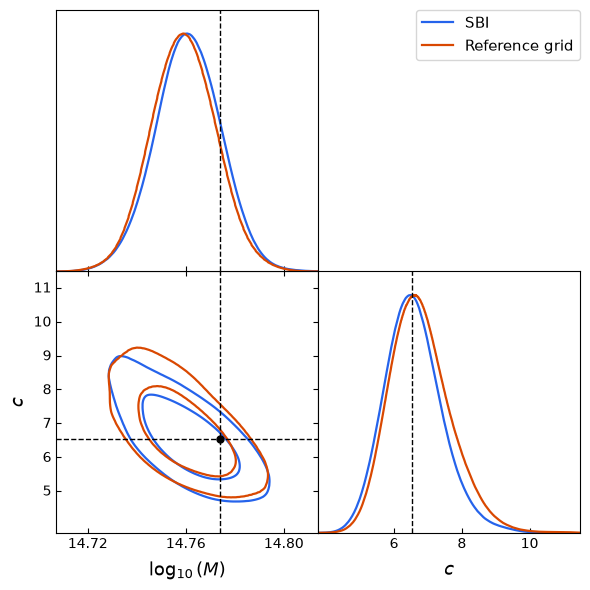

In [17]:
from getdist import MCSamples, plots
import matplotlib.pyplot as plt

names = ["log_mass", "concentration"]
labels = [r"\log_{10}(M)", r"c"]
ranges = {
    "log_mass": [prior_low[0], prior_high[0]],
    "concentration": [prior_low[1], prior_high[1]],
}

sbi_gd = MCSamples(
    samples=sbi_samples, names=names, labels=labels, ranges=ranges
)
grid_gd = MCSamples(
    samples=grid_samples, names=names, labels=labels, ranges=ranges
)

g = plots.get_subplot_plotter(subplot_size=3)
g.triangle_plot(
    [sbi_gd, grid_gd],
    params=names,
    filled=False,
    contour_colors=["#2563eb", "#d94801"],
    contour_lws=[1.6, 1.6],
    line_args=[
        {"color": "#2563eb", "lw": 1.6},
        {"color": "#d94801", "lw": 1.6},
    ],
    legend_labels=["SBI", "Reference grid"],
    markers=dict(zip(names, theta_true)),
    marker_args={"color": "black", "ls": "--", "lw": 1},
)
g.subplots[1, 0].plot(
    theta_true[0], theta_true[1], "ko", markersize=5, zorder=10
)
plt.show()